# Experiment 1: Introduction to Python and TensorFlow for Generative AI

**Aim:** Become familiar with Python scientific libraries and the TensorFlow / Keras API, and use them to build the
first building blocks of a generative model (tensors, automatic differentiation, a trainable network, and sampling).

## 1. Environment check

In [1]:
import os, sys, platform
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("Python     :", sys.version.split()[0])
print("Platform   :", platform.platform())
print("NumPy      :", np.__version__)
print("Matplotlib :", matplotlib.__version__)
print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("GPUs       :", tf.config.list_physical_devices("GPU") or "none (running on CPU)")

I0000 00:00:1792691332.215432    5021 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792691333.577972    5021 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Python     : 3.13.16
Platform   : Linux-6.18.44-fc-v140-x86_64-with-glibc2.39
NumPy      : 2.5.3
Matplotlib : 3.11.2
TensorFlow : 2.21.0
Keras      : 3.15.1
GPUs       : none (running on CPU)


## 2. Python basics used throughout the lab

In [2]:
def normalise(xs):
    lo, hi = min(xs), max(xs)
    return [(x - lo) / (hi - lo) for x in xs]

pixels = [0, 64, 128, 192, 255]
print("scaled pixels :", normalise(pixels))
config = {"latent_dim": 100, "batch_size": 64, "epochs": 5}
for k, v in config.items():
    print(f"{k:12s} = {v}")
squares = {n: n ** 2 for n in range(1, 6)}
print("squares       :", squares)

scaled pixels : [0.0, 0.25098039215686274, 0.5019607843137255, 0.7529411764705882, 1.0]
latent_dim   = 100
batch_size   = 64
epochs       = 5
squares       : {1: 1, 2: 4, 3: 9, 4: 16, 5: 25}


## 3. Tensors, shapes and broadcasting

In [3]:
a = tf.constant([[1., 2., 3.], [4., 5., 6.]])
b = tf.ones((2, 3)) * 2
print("a.shape, a.dtype :", a.shape, a.dtype)
print("a + b =\n", (a + b).numpy())
print("a @ a^T =\n", tf.matmul(a, a, transpose_b=True).numpy())
print("reshape(3,2) =\n", tf.reshape(a, (3, 2)).numpy())
print("column-wise mean :", tf.reduce_mean(a, axis=0).numpy())
print("broadcast a + [10,20,30] =\n", (a + tf.constant([10., 20., 30.])).numpy())
v = tf.Variable(tf.random.normal((2, 2), seed=1))
v.assign_add(tf.ones((2, 2)))
print("Variable after assign_add =\n", v.numpy())

a.shape, a.dtype : (2, 3) <dtype: 'float32'>
a + b =
 [[3. 4. 5.]
 [6. 7. 8.]]
a @ a^T =
 [[14. 32.]
 [32. 77.]]
reshape(3,2) =
 [[1. 2.]
 [3. 4.]
 [5. 6.]]
column-wise mean : [2.5 3.5 4.5]
broadcast a + [10,20,30] =
 [[11. 22. 33.]
 [14. 25. 36.]]
Variable after assign_add =
 [[ 0.18868178  2.4845986 ]
 [ 1.0653293  -1.4427042 ]]


## 4. Automatic differentiation with `GradientTape`
Generative models are trained by gradient descent on a loss, so we first check that TensorFlow's gradients match the
analytic derivative of $y = x^3 + 2x$, and then fit a straight line with a hand-written training loop.

In [4]:
x = tf.Variable(3.0)
with tf.GradientTape() as tape:
    y = x ** 3 + 2 * x
print("y        =", y.numpy())
print("dy/dx    =", tape.gradient(y, x).numpy(), "(analytic: 3x^2 + 2 = 29)")

y        = 33.0
dy/dx    = 29.0 (analytic: 3x^2 + 2 = 29)


step   0  loss 4.70001


step  30  loss 0.00932


step  60  loss 0.00242


step  90  loss 0.00229


step 120  loss 0.00228
learned w = 2.978 (true 3.0), b = 0.505 (true 0.5)


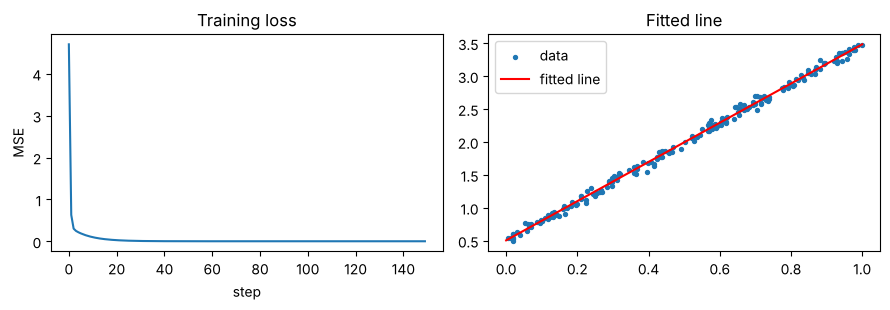

In [5]:
tf.random.set_seed(0); np.random.seed(0)
X = np.random.rand(200, 1).astype("float32")
Y = 3.0 * X + 0.5 + 0.05 * np.random.randn(200, 1).astype("float32")
w, c = tf.Variable([[0.0]]), tf.Variable([0.0])
opt = keras.optimizers.SGD(0.5)
losses = []
for step in range(150):
    with tf.GradientTape() as tape:
        loss = tf.reduce_mean((X @ w + c - Y) ** 2)
    g = tape.gradient(loss, [w, c])
    opt.apply_gradients(zip(g, [w, c]))
    losses.append(loss.numpy())
    if step % 30 == 0:
        print(f"step {step:3d}  loss {loss.numpy():.5f}")
print(f"learned w = {w.numpy()[0,0]:.3f} (true 3.0), b = {c.numpy()[0]:.3f} (true 0.5)")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(losses); ax[0].set_title("Training loss"); ax[0].set_xlabel("step"); ax[0].set_ylabel("MSE")
ax[1].scatter(X, Y, s=8, label="data")
xs = np.linspace(0, 1, 10)
ax[1].plot(xs, w.numpy()[0, 0] * xs + c.numpy()[0], "r", label="fitted line"); ax[1].legend()
ax[1].set_title("Fitted line")
plt.tight_layout(); plt.show()

## 5. A first neural network with Keras (MNIST classifier)
Keras `Sequential` API: define layers, compile with an optimiser and loss, then `fit`.

train images: (60000, 28, 28) uint8  labels: (60000,)
test images : (10000, 28, 28)
pixel range : 0 - 255


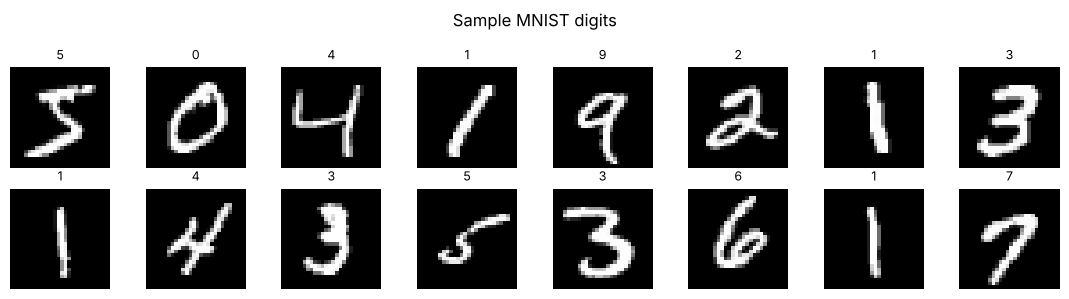

In [6]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("train images:", x_train.shape, x_train.dtype, " labels:", y_train.shape)
print("test images :", x_test.shape)
print("pixel range :", x_train.min(), "-", x_train.max())
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[i], cmap="gray"); ax.set_title(int(y_train[i]), fontsize=9); ax.axis("off")
plt.suptitle("Sample MNIST digits"); plt.tight_layout(); plt.show()

In [7]:
keras.utils.set_random_seed(42)
x_tr = (x_train / 255.0).astype("float32"); x_te = (x_test / 255.0).astype("float32")
model = keras.Sequential([
    keras.layers.Input((28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10, activation="softmax"),
])
model.summary(print_fn=print)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = model.fit(x_tr, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=2)
test_loss, test_acc = model.evaluate(x_te, y_test, verbose=0)
print(f"\nTest loss {test_loss:.4f}  |  Test accuracy {test_acc:.4f}")

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 101,770 (397.54 KB)
 Trainable params: 101,770 (397.54 KB)
 Non-trainable params: 0 (0.00 B)



Epoch 1/5


422/422 - 2s - 5ms/step - accuracy: 0.8788 - loss: 0.4249 - val_accuracy: 0.9543 - val_loss: 0.1740


Epoch 2/5


422/422 - 1s - 3ms/step - accuracy: 0.9394 - loss: 0.2084 - val_accuracy: 0.9648 - val_loss: 0.1235


Epoch 3/5


... (2 outputs left out)

422/422 - 1s - 3ms/step - accuracy: 0.9619 - loss: 0.1298 - val_accuracy: 0.9733 - val_loss: 0.0913


Epoch 5/5


422/422 - 1s - 3ms/step - accuracy: 0.9673 - loss: 0.1105 - val_accuracy: 0.9757 - val_loss: 0.0807



Test loss 0.0945  |  Test accuracy 0.9719


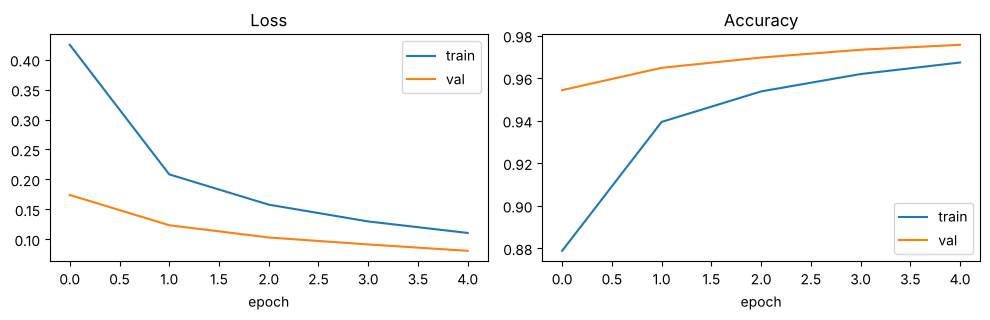

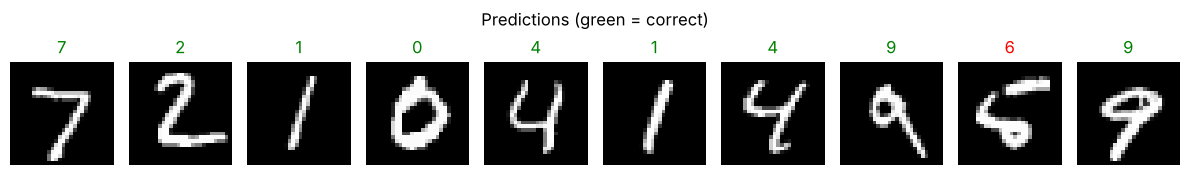

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()
pred = model.predict(x_te[:10], verbose=0)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for i, ax in enumerate(axes):
    ax.imshow(x_te[i], cmap="gray"); ax.axis("off")
    p = pred[i].argmax(); ax.set_title(f"{p}", color="g" if p == y_test[i] else "r")
plt.suptitle("Predictions (green = correct)"); plt.tight_layout(); plt.show()

## 6. First generative step: sampling from distributions
A generative model learns a distribution and then **samples** from it. Here we sample from a hand-built 2-D Gaussian
mixture with TensorFlow Probability-style operations written in plain TensorFlow, and then use a latent noise vector
fed through a (still untrained) network to see what "generation" means mechanically.

sample batch shape: (1500, 2) | empirical mean: [-0.351  0.389]
untrained generator output: (16, 28, 28) (noise z of size 64 -> 28x28 image)


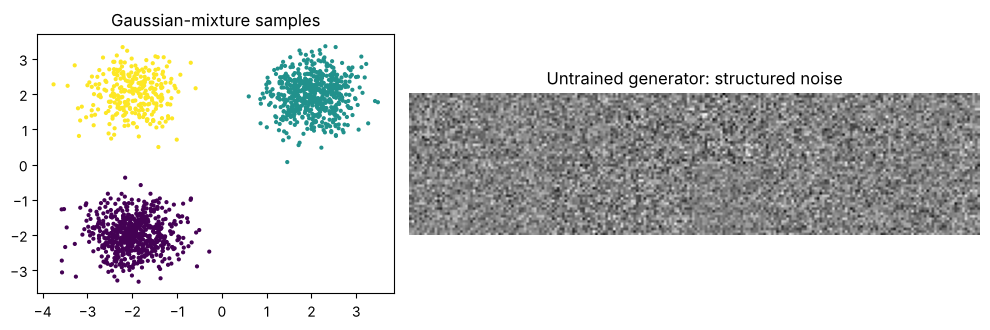

In [9]:
tf.random.set_seed(7)
means = tf.constant([[-2., -2.], [2., 2.], [-2., 2.]])
comp = tf.random.categorical(tf.math.log([[0.4, 0.4, 0.2]]), 1500)[0]
samples = tf.gather(means, comp) + 0.5 * tf.random.normal((1500, 2))
print("sample batch shape:", samples.shape, "| empirical mean:", samples.numpy().mean(0).round(3))

z = tf.random.normal((16, 64))
gen = keras.Sequential([keras.layers.Input((64,)), keras.layers.Dense(256, activation="relu"),
                        keras.layers.Dense(784, activation="sigmoid"), keras.layers.Reshape((28, 28))])
imgs = gen(z).numpy()
print("untrained generator output:", imgs.shape, "(noise z of size 64 -> 28x28 image)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].scatter(*samples.numpy().T, s=4, c=comp.numpy(), cmap="viridis"); ax[0].set_title("Gaussian-mixture samples")
grid = np.concatenate([np.concatenate(imgs[r * 8:(r + 1) * 8], axis=1) for r in range(2)], axis=0)
ax[1].imshow(grid, cmap="gray"); ax[1].axis("off"); ax[1].set_title("Untrained generator: structured noise")
plt.tight_layout(); plt.show()